<font size = 3 color="gray">Máster Universitario en inteligencia artificial (MUIA)</font> 

# Red neuronal sencilla con PyTorch (versión compacta)

La misma red que `bp_hardwired_ReLU` (2 entradas → 4 neuronas ReLU → 1 salida sigmoide, SGD con lotes de 100, η = 1, 100 épocas), con los mismos datos y los mismos pesos iniciales, escrita en el mínimo número de líneas:

* **`nn.Sequential`** en lugar de una clase propia.
* **`BCEWithLogitsLoss`**: integra la sigmoide en la pérdida, lo que es más estable numéricamente y algo más rápido. La red devuelve el *logit* $z$ y la clase es 1 si $z > 0$, que equivale a $\sigma(z) > 0.5$.
* **Datos generados y guardados directamente en el dispositivo** (GPU si existe) y lotes con `randperm(...).split(...)`, sin bucles sobre las muestras ni copias entre CPU y GPU durante el entrenamiento.

In [1]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Dispositivo:", torch.cuda.get_device_name(0) if device.type == "cuda" else device)
np.random.seed(2026); torch.manual_seed(2026)

def crea_datos(n):   # columnas x, y, etiqueta (frontera de tres regiones)
    x, y = np.random.rand(2, n)
    return torch.tensor(np.c_[x, y, (x**2 + y**2 < 0.7**2) | (x > 0.9)], dtype=torch.float32, device=device)

train, test = crea_datos(8000), crea_datos(2000)
model = nn.Sequential(nn.Linear(2, 4), nn.ReLU(), nn.Linear(4, 1)).to(device)
with torch.no_grad():   # He (capa ReLU) y Xavier (capa sigmoide), con los mismos valores que el original
    model[0].weight.copy_(torch.tensor(np.random.randn(4, 2) * np.sqrt(2 / 2))); model[0].bias.zero_()
    model[2].weight.copy_(torch.tensor(np.random.randn(1, 4) * np.sqrt(1 / 4))); model[2].bias.zero_()

acierto = lambda d: ((model(d[:, :2]) > 0).float() == d[:, 2:]).float().mean().item()
with torch.no_grad(): print(f"Tasa de acierto antes de entrenar: {acierto(train):.4f}")

Dispositivo: cpu


Tasa de acierto antes de entrenar: 0.5820


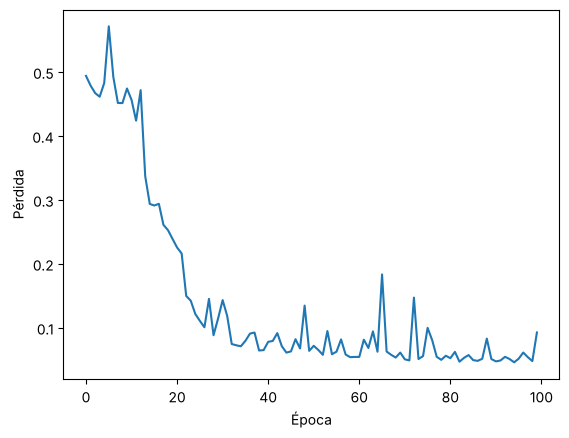

In [2]:
loss_fn, opt = nn.BCEWithLogitsLoss(), torch.optim.SGD(model.parameters(), lr=1)
X, y, history_cost = train[:, :2], train[:, 2:], []
for epoca in range(100):
    for idx in torch.randperm(len(X), device=device).split(100):
        opt.zero_grad(); loss_fn(model(X[idx]), y[idx]).backward(); opt.step()
    with torch.no_grad(): history_cost.append(loss_fn(model(X), y).item())

plt.plot(history_cost); plt.xlabel("Época"); plt.ylabel("Pérdida"); plt.show()

Tasa de acierto en test: 0.9610


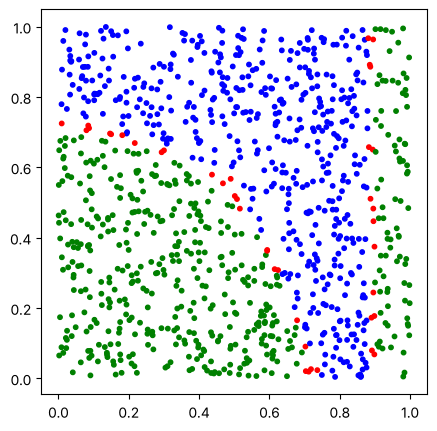

In [3]:
with torch.no_grad():
    print(f"Tasa de acierto en test: {acierto(test):.4f}")
    t = test[:1000].cpu().numpy(); pred = (model(test[:1000, :2]) > 0).float().cpu().numpy().ravel()
plt.figure(figsize=(5, 5)); plt.gca().set_aspect("equal")
plt.scatter(t[:, 0], t[:, 1], s=10, c=np.where(pred != t[:, 2], "red", np.where(pred == 1, "green", "blue"))); plt.show()

---

<font size="1" color="grey">
    (c) 2026 Javier García Algarra. <a href='https://www.u-tad.com'>www.u-tad.com</a> <br>
Licensed under a Creative Commons Reconocimiento 4.0 Internacional License
</font>